<a href="https://colab.research.google.com/github/Bio-dot/cvd-women--S-K/blob/main/02_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 02 Analysis: Track 2, Cardiovascular Health in Women

This notebook follows steps 3 to 7 of the [workflow](../../3-workflow.md): explore, build a model, check it, interpret and make a headline visual.

Run `01_cleaning.ipynb` first. Settings marked **You decide** start as `None`.

In [3]:
# Setup: run this cell first. It finds the track folder and the data.
import re, sys, subprocess
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PUBLIC_REPO = "https://github.com/Harvard-Undergraduate-OpenBio/openbio-datathon-2026.git"
IN_COLAB = "google.colab" in sys.modules

def find_track_dir():
    here = Path.cwd().resolve()
    for folder in [here, *here.parents]:
        if (folder / "track-02" / "data").is_dir():
            return folder / "track-02"
        if folder.name == "track-02" and (folder / "data").is_dir():
            return folder
    if IN_COLAB:
        dest = Path("/content/openbio-datathon-2026")
        if not dest.exists():
            subprocess.run(["git", "clone", "--depth", "1", PUBLIC_REPO, str(dest)], check=True)
        return dest / "track-02"
    return None

TRACK = find_track_dir()
TEAM = TRACK / "team" if TRACK else Path.cwd()
CLEAN = TEAM / "data_clean"
FIGURES = TEAM / "figures"
for folder in (CLEAN, FIGURES, TEAM / "docs"):
    folder.mkdir(parents=True, exist_ok=True)

SEARCH_DIRS = [d for d in [TRACK / "data" if TRACK else None, TRACK / "data" / "gbd" if TRACK else None,
               Path.cwd(), Path("/content"), Path("/content/drive/MyDrive/datathon")] if d]

def missing(name):
    print(f"Fill in {name} in the cell above, then rerun this cell.")

print("Track folder:", TRACK)
print("Team folder: ", TEAM)
if IN_COLAB:
    print("On Colab, outputs are saved in this session only. Download them or copy them into your team repository.")


Track folder: /content/openbio-datathon-2026/track-02
Team folder:  /content/openbio-datathon-2026/track-02/team
On Colab, outputs are saved in this session only. Download them or copy them into your team repository.


## Step 1: Your question

**You decide:**

- `QUESTION`: one sentence, also written in your team README.
- `DATASET`: `"d1"`, `"d2"`, `"s1"`, `"s2"` or `"s2_long"`.
- `OUTCOME`: the column you want to explain.
- `PREDICTORS`: a list of columns. Wrap ordered or text categories in `C()`, for example `"C(cholesterol_level)"`.
- `MODEL`: `"logistic"` for a yes/no outcome or `"linear"` for a number.

In [4]:
QUESTION = "Among records coded as women in Dataset 1, how are age, blood pressure, cholesterol, and glucose associated with the recorded CVD label?"
DATASET = "d1"
OUTCOME = "cardio"
PREDICTORS = [
    "age_years",
    "ap_hi",
    "ap_lo",
    "C(cholesterol_level)",
    "C(gluc_level)"
]
MODEL = "logistic"

READY = all(v is not None for v in (QUESTION, DATASET, OUTCOME, PREDICTORS, MODEL))
if not READY:
    print("Fill in QUESTION, DATASET, OUTCOME, PREDICTORS and MODEL, then rerun the notebook.")
    print("Example: DATASET='d1', OUTCOME='cardio', PREDICTORS=['age_years', 'C(cholesterol_level)'], MODEL='logistic'")


In [5]:
df = None
if READY:
    path = CLEAN / f"{DATASET}_clean.csv"
    # If the cleaned Dataset 1 file is missing, rebuild it from the raw data.
    if DATASET == "d1" and not path.exists():
        raw_path = TRACK / "data" / "cardiovascular_dataset_OpenBio_Final.csv"

        if raw_path.exists():
            rebuilt = pd.read_csv(raw_path, sep=";")
            rebuilt = rebuilt.drop_duplicates(subset="id").copy()
            rebuilt = rebuilt.loc[rebuilt["gender"] == 1].copy()
            rebuilt["age_years"] = rebuilt["age"] / 365.25

            rebuilt = rebuilt.loc[
                rebuilt["ap_hi"].between(70, 250)
                & rebuilt["ap_lo"].between(40, 150)
            ].copy()
            rebuilt = rebuilt.loc[rebuilt["ap_hi"] > rebuilt["ap_lo"]].copy()

            levels = {1: "normal", 2: "above normal", 3: "well above normal"}
            ordered_levels = ["normal", "above normal", "well above normal"]

            for col in ("cholesterol", "gluc"):
                rebuilt[col + "_level"] = pd.Categorical(
                    rebuilt[col].map(levels),
                    categories=ordered_levels,
                    ordered=True
                )

            path.parent.mkdir(parents=True, exist_ok=True)
            rebuilt.to_csv(path, index=False)
            print(f"Rebuilt {path.name}: {len(rebuilt):,} rows")
        else:
            print(f"Raw Dataset 1 file not found at {raw_path}")
    if not path.exists():
        print(f"{path.name} not found. Run 01_cleaning.ipynb first.")
        READY = False
    else:
        df = pd.read_csv(path)
        for col in [c for c in df.columns if c.endswith("_level")]:
            order = {"cholesterol_level": ["normal", "above normal", "well above normal"],
                     "gluc_level": ["normal", "above normal", "well above normal"],
                     "alcohol_level": ["None", "Light", "Moderate", "Heavy"],
                     "diet_level": ["Unhealthy", "Average", "Healthy"]}.get(col)
            if order:
                df[col] = pd.Categorical(df[col], categories=order, ordered=True)
        print(QUESTION)
        print(f"Loaded {len(df):,} rows from {path.name}")

Rebuilt d1_clean.csv: 44,727 rows
Among records coded as women in Dataset 1, how are age, blood pressure, cholesterol, and glucose associated with the recorded CVD label?
Loaded 44,727 rows from d1_clean.csv


In [6]:
print(df[["age_years", "ap_hi", "ap_lo",
          "cholesterol_level", "gluc_level", "cardio"]].head())
print(df["cardio"].value_counts(dropna=False))

   age_years  ap_hi  ap_lo  cholesterol_level    gluc_level  cardio
0  55.381246    140     90  well above normal        normal       1
1  51.627652    130     70  well above normal        normal       1
2  47.841205    100     60             normal        normal       0
3  59.997262    120     80       above normal  above normal       0
4  60.542094    130     80  well above normal        normal       0
cardio
0    22716
1    22011
Name: count, dtype: int64


## Step 2: Explore

Sample size, summary statistics and each predictor plotted against the outcome. Note anything surprising.

Rows with no missing values in these columns: 44,727 of 44,727


,cardio,age_years,ap_hi,ap_lo,cholesterol_level,gluc_level
count,44727.00,44727.00,44727.00,44727.00,44727,44727
unique,NaN,NaN,NaN,NaN,3,3
top,NaN,NaN,NaN,NaN,normal,normal
freq,NaN,NaN,NaN,NaN,33036,37810
mean,0.49,53.41,125.91,80.84,NaN,NaN
std,0.50,6.66,16.72,9.48,NaN,NaN
min,0.00,29.73,70.00,40.00,NaN,NaN
25%,0.00,49.38,120.00,80.00,NaN,NaN
50%,0.00,54.00,120.00,80.00,NaN,NaN
75%,1.00,58.39,140.00,90.00,NaN,NaN


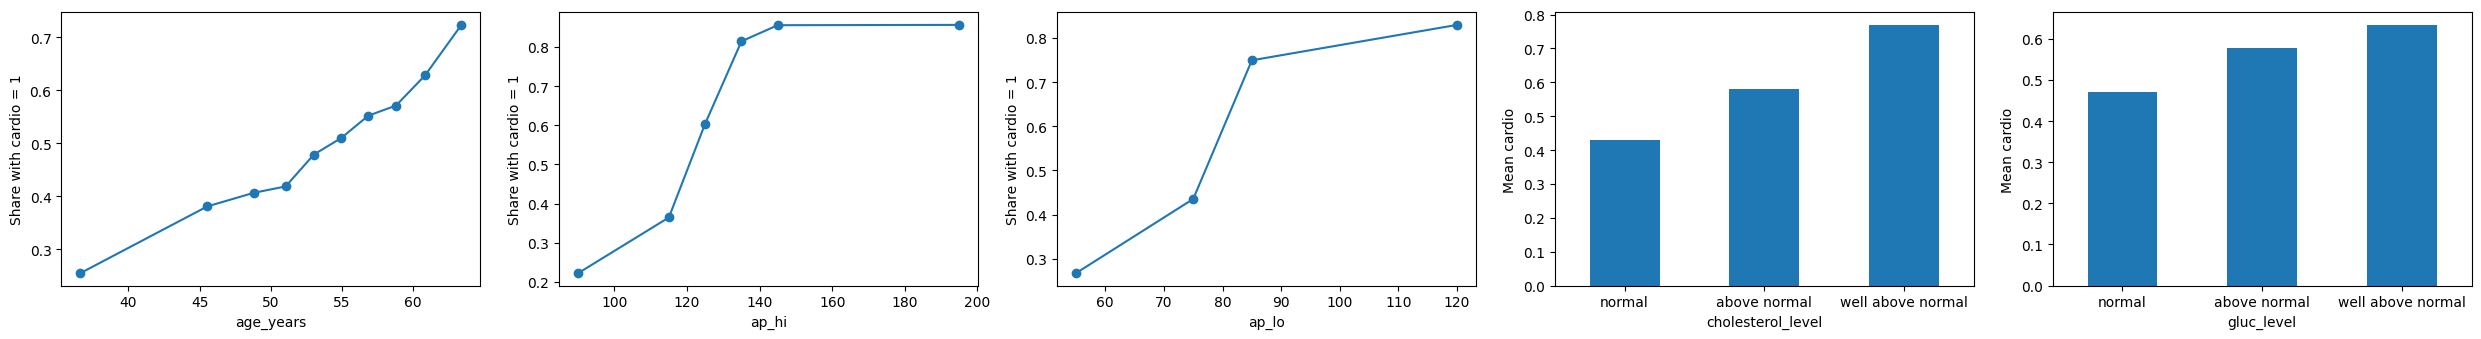

In [7]:
def base_column(term):
    m = re.match(r"C\((\w+)", term)
    return m.group(1) if m else term

def nice_term(term):
    """'C(cholesterol_level)[T.above normal]' -> 'cholesterol_level: above normal'."""
    m = re.match(r"C\((\w+)[^)]*\)\[T\.(.+)\]", term)
    return f"{m.group(1)}: {m.group(2)}" if m else term

if READY:
    cols = [OUTCOME] + [base_column(p) for p in PREDICTORS]
    data = df[cols].dropna()
    print(f"Rows with no missing values in these columns: {len(data):,} of {len(df):,}")
    display(data.describe(include="all").round(2))

    fig, axes = plt.subplots(1, len(PREDICTORS), figsize=(5 * len(PREDICTORS), 3.5), squeeze=False)
    for ax, term in zip(axes[0], PREDICTORS):
        col = base_column(term)
        if term.startswith("C(") or data[col].nunique() <= 10:
            data.groupby(col, observed=True)[OUTCOME].mean().plot.bar(ax=ax, rot=0)
            ax.set_ylabel(f"Mean {OUTCOME}")
        elif MODEL == "logistic":
            binned = pd.qcut(data[col], 10, duplicates="drop")
            share = data.groupby(binned, observed=True)[OUTCOME].mean()
            ax.plot([b.mid for b in share.index], share.values, marker="o")
            ax.set_ylabel(f"Share with {OUTCOME} = 1")
        else:
            sample = data.sample(min(len(data), 3000), random_state=0)
            ax.scatter(sample[col], sample[OUTCOME], s=5, alpha=0.3)
            ax.set_ylabel(OUTCOME)
        ax.set_xlabel(col)
    plt.tight_layout()
    plt.show()


In [9]:
df[["ap_hi", "ap_lo"]].corr()

,ap_hi,ap_lo
ap_hi,1.000000,0.740164
ap_lo,0.740164,1.000000


## Step 3: Build the model

- **Logistic:** prints odds ratios (OR) with 95% confidence intervals and draws a forest plot. OR = 1 means no association.
- **Linear:** prints the slope and R². If you have one numeric predictor, it draws the fitted line with a confidence band.

Formula: cardio ~ age_years + ap_hi + ap_lo + C(cholesterol_level) + C(gluc_level)


,OR,CI low,CI high,p-value
cholesterol_level: above normal,1.454,1.362,1.552,0.000
cholesterol_level: well above normal,3.078,2.826,3.353,0.000
gluc_level: above normal,1.034,0.947,1.128,0.455
gluc_level: well above normal,0.745,0.677,0.819,0.000
age_years,1.057,1.054,1.061,0.000
ap_hi,1.059,1.056,1.061,0.000
ap_lo,1.012,1.009,1.016,0.000


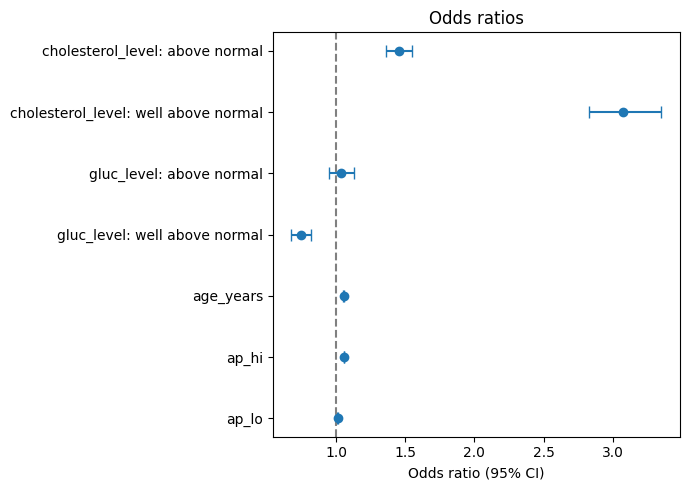

In [10]:
import statsmodels.formula.api as smf

result = None
if READY:
    formula = f"{OUTCOME} ~ " + " + ".join(PREDICTORS)
    print("Formula:", formula)
    if MODEL == "logistic":
        result = smf.logit(formula, data=data).fit(disp=False)
        table = pd.DataFrame({"OR": np.exp(result.params),
                              "CI low": np.exp(result.conf_int()[0]),
                              "CI high": np.exp(result.conf_int()[1]),
                              "p-value": result.pvalues}).drop(index="Intercept")
        table.index = [nice_term(i) for i in table.index]
        display(table.round(3))

        fig, ax = plt.subplots(figsize=(7, 0.5 * len(table) + 1.5))
        y = np.arange(len(table))[::-1]
        ax.errorbar(table["OR"], y, xerr=[table["OR"] - table["CI low"], table["CI high"] - table["OR"]],
                    fmt="o", capsize=4)
        ax.axvline(1, color="grey", linestyle="--")
        ax.set_yticks(y, table.index)
        ax.set_xlabel("Odds ratio (95% CI)")
        ax.set_title("Odds ratios")
        plt.tight_layout()
        fig.savefig(FIGURES / "forest_plot.png", dpi=200)
        plt.show()
    elif MODEL == "linear":
        result = smf.ols(formula, data=data).fit()
        table = pd.DataFrame({"Slope": result.params, "CI low": result.conf_int()[0],
                              "CI high": result.conf_int()[1], "p-value": result.pvalues})
        table.index = [nice_term(i) for i in table.index]
        display(table.round(3))
        print(f"R-squared: {result.rsquared:.3f}   n = {int(result.nobs):,}")

        if len(PREDICTORS) == 1 and not PREDICTORS[0].startswith("C("):
            x = PREDICTORS[0]
            grid = pd.DataFrame({x: np.linspace(data[x].min(), data[x].max(), 100)})
            band = result.get_prediction(grid).summary_frame(alpha=0.05)
            sample = data.sample(min(len(data), 3000), random_state=0)
            fig, ax = plt.subplots(figsize=(7, 4.5))
            ax.scatter(sample[x], sample[OUTCOME], s=6, alpha=0.3)
            ax.plot(grid[x], band["mean"], color="C1")
            ax.fill_between(grid[x], band["mean_ci_lower"], band["mean_ci_upper"], color="C1", alpha=0.3)
            ax.set_xlabel(x)
            ax.set_ylabel(OUTCOME)
            ax.set_title(f"Slope {result.params[x]:.2f}, R\u00b2 {result.rsquared:.2f}")
            plt.tight_layout()
            fig.savefig(FIGURES / "regression_line.png", dpi=200)
            plt.show()
    else:
        print('MODEL must be "logistic" or "linear".')


## Step 4: Check your work

- **Logistic:** fits on 80% of the rows and reports the AUC on the other 20%. 0.5 is a coin flip, 1 is perfect.
- **Linear:** plots residuals against fitted values. A clear curve or funnel shape means a straight line is a poor fit.

Then change one decision (a cleaning range or a predictor) and rerun to see whether your main result holds.

Held-out AUC: 0.787 (train n = 35,781, test n = 8,946)


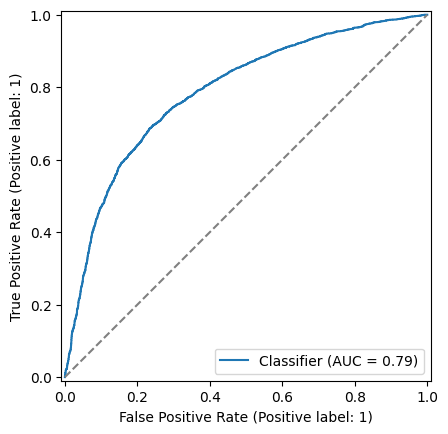

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, RocCurveDisplay

if READY and result is not None:
    if MODEL == "logistic":
        train, test = train_test_split(data, test_size=0.2, random_state=42, stratify=data[OUTCOME])
        holdout = smf.logit(formula, data=train).fit(disp=False)
        prob = holdout.predict(test)
        auc = roc_auc_score(test[OUTCOME], prob)
        print(f"Held-out AUC: {auc:.3f} (train n = {len(train):,}, test n = {len(test):,})")
        RocCurveDisplay.from_predictions(test[OUTCOME], prob)
        plt.plot([0, 1], [0, 1], "--", color="grey")
        plt.show()
    else:
        fig, ax = plt.subplots(figsize=(6, 4))
        ax.scatter(result.fittedvalues, result.resid, s=5, alpha=0.3)
        ax.axhline(0, color="grey", linestyle="--")
        ax.set_xlabel("Fitted value")
        ax.set_ylabel("Residual")
        plt.tight_layout()
        plt.show()


In [12]:
data[["ap_hi", "ap_lo"]].corr()

,ap_hi,ap_lo
ap_hi,1.000000,0.740164
ap_lo,0.740164,1.000000


In [13]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

# Use identical records for both models
comparison_data = df[
    ["cardio", "age_years", "ap_hi", "ap_lo",
     "cholesterol_level", "gluc_level"]
].dropna().copy()

primary_formula = (
    "cardio ~ age_years + ap_hi + ap_lo "
    "+ C(cholesterol_level) + C(gluc_level)"
)
sensitivity_formula = (
    "cardio ~ age_years + ap_hi "
    "+ C(cholesterol_level) + C(gluc_level)"
)

primary_fit = smf.logit(primary_formula, data=comparison_data).fit(disp=False)
sensitivity_fit = smf.logit(sensitivity_formula, data=comparison_data).fit(disp=False)

def make_or_table(fit):
    ci = fit.conf_int()
    table = pd.DataFrame({
        "OR": np.exp(fit.params),
        "CI low": np.exp(ci[0]),
        "CI high": np.exp(ci[1])
    }).drop(index="Intercept", errors="ignore")
    return table.round(3)

print("Primary model — includes systolic and diastolic BP")
display(make_or_table(primary_fit))

print("Sensitivity model — omits diastolic BP")
display(make_or_table(sensitivity_fit))

# Same random train/test split for a fair AUC comparison
train, test = train_test_split(
    comparison_data, test_size=0.2, random_state=42,
    stratify=comparison_data["cardio"]
)

primary_holdout = smf.logit(primary_formula, data=train).fit(disp=False)
sensitivity_holdout = smf.logit(sensitivity_formula, data=train).fit(disp=False)

print("Primary model AUC:",
      round(roc_auc_score(test["cardio"], primary_holdout.predict(test)), 3))
print("Sensitivity model AUC:",
      round(roc_auc_score(test["cardio"], sensitivity_holdout.predict(test)), 3))

Primary model — includes systolic and diastolic BP


,OR,CI low,CI high
C(cholesterol_level)[T.above normal],1.454,1.362,1.552
C(cholesterol_level)[T.well above normal],3.078,2.826,3.353
C(gluc_level)[T.above normal],1.034,0.947,1.128
C(gluc_level)[T.well above normal],0.745,0.677,0.819
age_years,1.057,1.054,1.061
ap_hi,1.059,1.056,1.061
ap_lo,1.012,1.009,1.016


Sensitivity model — omits diastolic BP


,OR,CI low,CI high
C(cholesterol_level)[T.above normal],1.455,1.363,1.553
C(cholesterol_level)[T.well above normal],3.099,2.845,3.375
C(gluc_level)[T.above normal],1.037,0.950,1.131
C(gluc_level)[T.well above normal],0.743,0.675,0.817
age_years,1.057,1.054,1.061
ap_hi,1.064,1.062,1.066


Primary model AUC: 0.787
Sensitivity model AUC: 0.786


## Step 5: Interpret

Write your main result as one plain sentence with the effect size and its confidence interval, then check it against the [ground rules](../../README.md#ground-rules). Say "associated with," not "causes."

**Your sentence:** Among the 44,727 records coded as women and after adjusting for age, systolic and diastolic blood pressure, and glucose (95% CI 2.83–3.35), having a well above normal cholesterol category was associated with 3.08 times the odds of a recorded CVD label compared to the normal category.

## Step 6: Headline visual

One graph for a non-specialist, used in both the video and the article.

**You decide:** a title that states the finding in plain words, and everyday axis labels with units. `HEADLINE_TERMS` picks which model terms to show (logistic) and `LABELS` renames them.

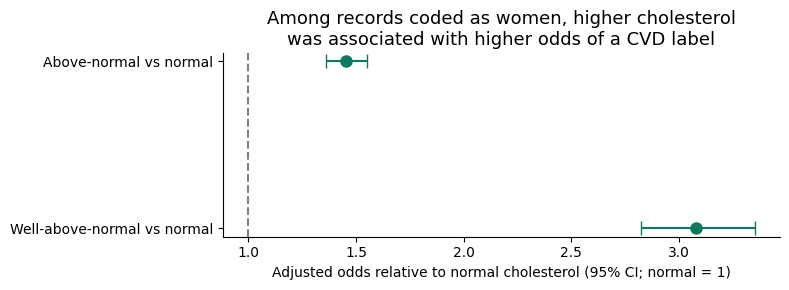

Saved /content/openbio-datathon-2026/track-02/team/figures/headline.png


In [14]:
HEADLINE_TITLE = ("Among records coded as women, higher cholesterol\n" "was associated with higher odds of a CVD label")    # e.g. "Higher cholesterol is linked to higher odds of heart disease in women"
X_LABEL = "Adjusted odds relative to normal cholesterol (95% CI; normal = 1)"
Y_LABEL = None
HEADLINE_TERMS = ["cholesterol_level: above normal",
    "cholesterol_level: well above normal"    # logistic only: list of terms from the OR table, or None for all
]
LABELS = {
    "cholesterol_level: above normal": "Above-normal vs normal",
    "cholesterol_level: well above normal": "Well-above-normal vs normal"
}              # e.g. {"age_years": "Age (per year)"}

if READY and result is not None:
    if HEADLINE_TITLE is None:
        missing("HEADLINE_TITLE")
    fig, ax = plt.subplots(figsize=(8, 5))
    if MODEL == "logistic":
        t = table if HEADLINE_TERMS is None else table.loc[HEADLINE_TERMS]
        fig.set_size_inches(8, max(3, 1.5 + 0.7 * len(t)))
        y = np.arange(len(t))[::-1]
        ax.errorbar(t["OR"], y, xerr=[t["OR"] - t["CI low"], t["CI high"] - t["OR"]],
                    fmt="o", markersize=8, capsize=5, color="#0b7a5e")
        ax.axvline(1, color="grey", linestyle="--")
        ax.set_yticks(y, [LABELS.get(i, i) for i in t.index])
        ax.set_xlabel(X_LABEL or "Odds ratio (95% confidence interval)")
    elif len(PREDICTORS) == 1 and not PREDICTORS[0].startswith("C("):
        ax.scatter(sample[x], sample[OUTCOME], s=6, alpha=0.2, color="grey")
        ax.plot(grid[x], band["mean"], color="#0b7a5e", linewidth=2.5)
        ax.fill_between(grid[x], band["mean_ci_lower"], band["mean_ci_upper"], color="#0b7a5e", alpha=0.25)
        ax.set_xlabel(X_LABEL or x)
        ax.set_ylabel(Y_LABEL or OUTCOME)
    else:
        t = table.drop(index="Intercept")
        fig.set_size_inches(8, max(3, 1.5 + 0.7 * len(t)))
        y = np.arange(len(t))[::-1]
        ax.errorbar(t["Slope"], y, xerr=[t["Slope"] - t["CI low"], t["CI high"] - t["Slope"]],
                    fmt="o", markersize=8, capsize=5, color="#0b7a5e")
        ax.axvline(0, color="grey", linestyle="--")
        ax.set_yticks(y, [LABELS.get(i, i) for i in t.index])
        ax.set_xlabel(X_LABEL or f"Change in {OUTCOME} per unit (95% confidence interval)")
    ax.set_title(HEADLINE_TITLE or "Add a title that states your finding", fontsize=13)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    plt.tight_layout()
    fig.savefig(FIGURES / "headline.png", dpi=300)
    plt.show()
    print("Saved", FIGURES / "headline.png")


In [ ]:
from google.colab import files
files.download(str(FIGURES / "headline.png"))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

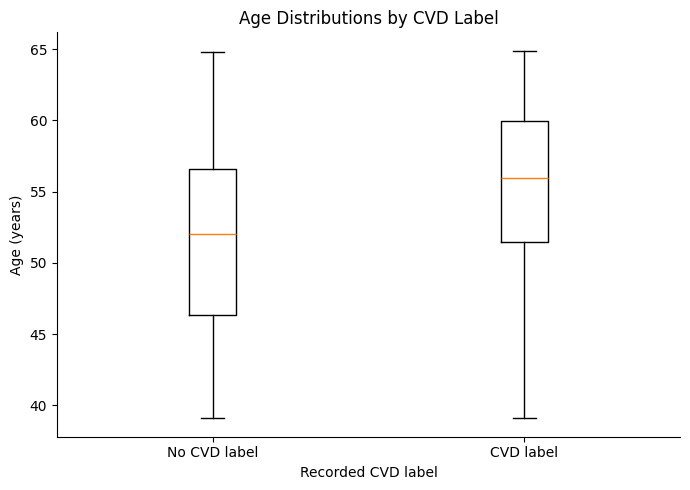

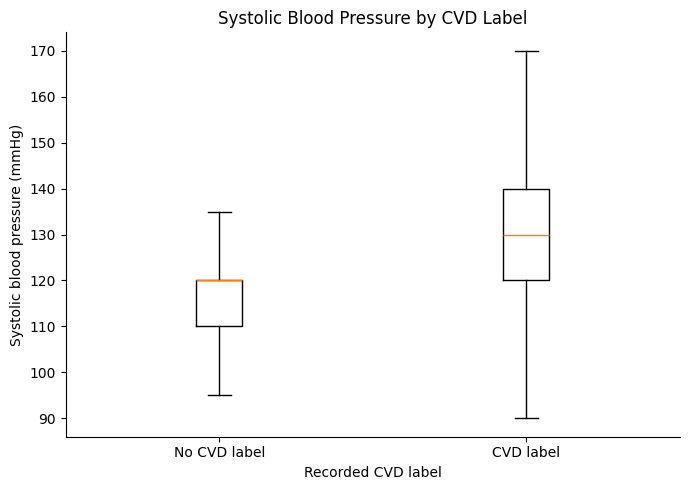

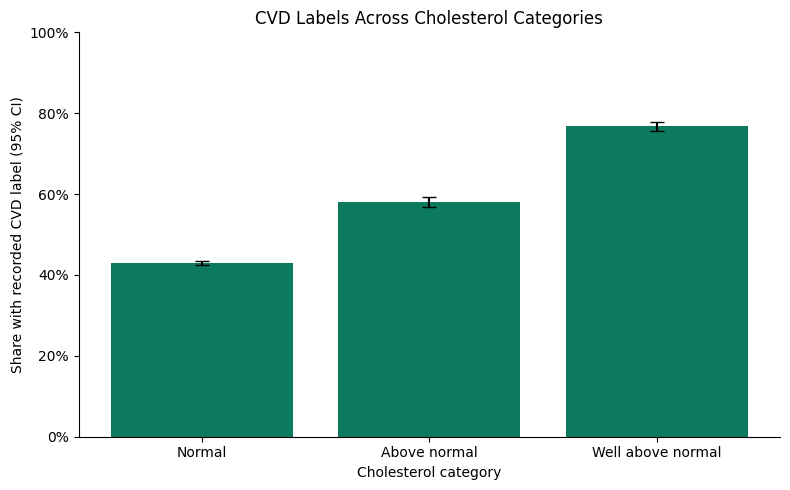

Records shown by cholesterol category: [33036, 6255, 5436]
Saved Figures 2–4 to: /content/openbio-datathon-2026/track-02/team/figures


In [15]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

FIGURES.mkdir(parents=True, exist_ok=True)

# Use only the columns needed for these descriptive charts.
plot_df = df[["cardio", "age_years", "ap_hi", "cholesterol_level"]].dropna().copy()
plot_df["CVD label"] = plot_df["cardio"].map({
    0: "No CVD label",
    1: "CVD label"
})

# Figure 2: Age distributions by recorded CVD label
fig, ax = plt.subplots(figsize=(7, 5))
groups = [
    plot_df.loc[plot_df["cardio"] == value, "age_years"]
    for value in [0, 1]
]
ax.boxplot(
    groups,
    tick_labels=["No CVD label", "CVD label"],
    showfliers=False
)
ax.set_title("Age Distributions by CVD Label")
ax.set_xlabel("Recorded CVD label")
ax.set_ylabel("Age (years)")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
fig.savefig(FIGURES / "age_by_cvd_label.png", dpi=300, bbox_inches="tight")
plt.show()


# Figure 3: Systolic blood-pressure distributions by recorded CVD label
fig, ax = plt.subplots(figsize=(7, 5))
groups = [
    plot_df.loc[plot_df["cardio"] == value, "ap_hi"]
    for value in [0, 1]
]
ax.boxplot(
    groups,
    tick_labels=["No CVD label", "CVD label"],
    showfliers=False
)
ax.set_title("Systolic Blood Pressure by CVD Label")
ax.set_xlabel("Recorded CVD label")
ax.set_ylabel("Systolic blood pressure (mmHg)")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
fig.savefig(FIGURES / "systolic_bp_by_cvd_label.png", dpi=300, bbox_inches="tight")
plt.show()


# Figure 4: Share with a CVD label by cholesterol category,
# with 95% Wilson confidence intervals.
def wilson_ci(successes, total, z=1.96):
    proportion = successes / total
    denominator = 1 + z**2 / total
    center = (proportion + z**2 / (2 * total)) / denominator
    margin = (
        z * np.sqrt(proportion * (1 - proportion) / total + z**2 / (4 * total**2))
        / denominator
    )
    return center - margin, center + margin


chol_order = ["normal", "above normal", "well above normal"]
chol_labels = ["Normal", "Above normal", "Well above normal"]

shares, lower, upper, counts = [], [], [], []

for category in chol_order:
    group = plot_df.loc[plot_df["cholesterol_level"] == category, "cardio"]
    n = len(group)
    positives = int(group.sum())
    share = positives / n
    low, high = wilson_ci(positives, n)

    shares.append(share)
    lower.append(low)
    upper.append(high)
    counts.append(n)

x = np.arange(len(chol_order))
yerr = np.array([np.array(shares) - np.array(lower),
                 np.array(upper) - np.array(shares)])

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(x, shares, color="#0b7a5e")
ax.errorbar(x, shares, yerr=yerr, fmt="none", ecolor="black", capsize=5)
ax.set_xticks(x, chol_labels)
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_title("CVD Labels Across Cholesterol Categories")
ax.set_xlabel("Cholesterol category")
ax.set_ylabel("Share with recorded CVD label (95% CI)")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
fig.savefig(FIGURES / "cvd_label_by_cholesterol.png", dpi=300, bbox_inches="tight")
plt.show()

print("Records shown by cholesterol category:", counts)
print("Saved Figures 2–4 to:", FIGURES)

---

This notebook is part of a student data analysis. It is not medical advice, a diagnostic tool or clinical guidance.